# Score-based generative modelling with natural gradient descent (PyTorch)

This notebook trains a small **score-based diffusion model** in the SDE formulation of
[Song et al. (2021)](https://arxiv.org/abs/2011.13456). It compares Adam with natural gradient descent, solving
each NGD step classically or with the simulated HHL quantum linear solver. The companion notebook
[`ngd_diffusion_torch.ipynb`](ngd_diffusion_torch.ipynb) covers the discrete DDPM formulation.

**Forward SDE.** Data is diffused by the variance-preserving (VP) SDE
$\mathrm dx = -\tfrac12\beta(t)\,x\,\mathrm dt + \sqrt{\beta(t)}\,\mathrm dW$ for $t\in[0,1]$, with
$\beta(t)=\beta_{\min}+t(\beta_{\max}-\beta_{\min})$. Its marginals are Gaussian:
$x_t = m_t x_0 + \sigma_t z$ with $z\sim\mathcal N(0,I)$, $m_t = e^{-\frac12\int_0^t\beta}$ and $\sigma_t^2 = 1-m_t^2$.

**Score matching.** A network $s_\theta(x,t)$ learns the score $\nabla_x\log p_t(x)$ by *denoising score matching*,
using Song et al.'s weighting $\lambda(t)=\sigma_t^2$:

$$L(\theta) = \tfrac12\,\mathbb E_{t,x_0,z}\,\big\|\sigma_t\,s_\theta(x_t,t) + z\big\|^2 .$$

[Vincent (2011)](https://doi.org/10.1162/NECO_a_00142) showed that this equals the weighted score error
$\tfrac12\mathbb E\,\sigma_t^2\|s_\theta - \nabla\log p_t\|^2$ plus a constant. So minimising it fits the true score,
but its minimum is not zero. With the usual parametrisation $s_\theta = \mathrm{net}_\theta(x,t)/\sigma_t$, the loss
is a sum of squared residuals $r = \mathrm{net}_\theta(x_t,t) + z$, which is what `metric="gauss_newton"` expects.

**Sampling.** The model generates data by integrating backwards in time, with the reverse SDE
$\mathrm dx = [-\tfrac12\beta x - \beta\,s_\theta]\,\mathrm dt + \sqrt\beta\,\mathrm d\bar W$, the deterministic
**probability-flow ODE** $\mathrm dx/\mathrm dt = -\tfrac12\beta x - \tfrac12\beta\,s_\theta$, or a
**predictor-corrector** scheme that adds Langevin steps.

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn

from hybrid_ngd import QiskitHHLSolver
from hybrid_ngd.torch_ngd import NGD

torch.set_default_dtype(torch.float64)
warnings.filterwarnings("ignore", message="Condition number exceeds")  # plain HHL drops small eigenvalues, see the DDPM notebook

In [2]:
# Plot styling, shared with the other example notebooks.
SURFACE, INK, INK_2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
COLORS = {"Adam": "#2a78d6", "NGD (direct)": "#eb6834", "NGD (HHL)": "#1baf7a"}

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK_2, "axes.titlecolor": INK, "axes.titlesize": 11,
    "axes.edgecolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "lines.linewidth": 2, "legend.frameon": False,
})


def square_panel(ax, title):
    ax.set(title=title, xlim=(-2.4, 2.4), ylim=(-2.4, 2.4), aspect="equal")
    ax.set_xticks([-2, 0, 2]), ax.set_yticks([-2, 0, 2])


def scatter_panel(ax, points, color, title):
    ax.scatter(points[:, 0], points[:, 1], s=6, color=color, alpha=0.5, linewidths=0)
    square_panel(ax, title)

## 1. The VP SDE and an analytic score

The data is a mixture of four Gaussians with standard deviation $s_0 = 0.15$. Every noised marginal is then also
a Gaussian mixture, $p_t = \tfrac14\sum_k \mathcal N(m_t\mu_k,\ (m_t^2 s_0^2 + \sigma_t^2)\,I)$, so the **true score**
is available in closed form. That gives an exact measure of how well each model has learned it.

In [3]:
BETA_MIN, BETA_MAX, T_MIN = 0.1, 20.0, 1e-3  # Song et al.'s VP settings; T_MIN avoids sigma_t -> 0
CENTERS, S0 = torch.tensor([[1.0, 1.0], [-1.0, 1.0], [-1.0, -1.0], [1.0, -1.0]]), 0.15


def beta(t):
    return BETA_MIN + t * (BETA_MAX - BETA_MIN)


def mean_coef(t):
    return torch.exp(-0.25 * t**2 * (BETA_MAX - BETA_MIN) - 0.5 * t * BETA_MIN)


def sigma(t):
    return (1 - mean_coef(t) ** 2).sqrt()


def sample_data(n, generator):
    return CENTERS[torch.randint(0, 4, (n,), generator=generator)] + S0 * torch.randn(n, 2, generator=generator)


def true_score(x, t):
    m, s = mean_coef(t)[:, None], sigma(t)[:, None]
    var = m**2 * S0**2 + s**2
    offsets = m[:, None, :] * CENTERS[None] - x[:, None, :]  # [N, components, 2]
    weights = torch.softmax(-(offsets**2).sum(-1) / (2 * var), dim=1)
    return (weights[..., None] * offsets).sum(1) / var


reference = sample_data(2000, torch.Generator().manual_seed(99))  # held-out samples for scoring

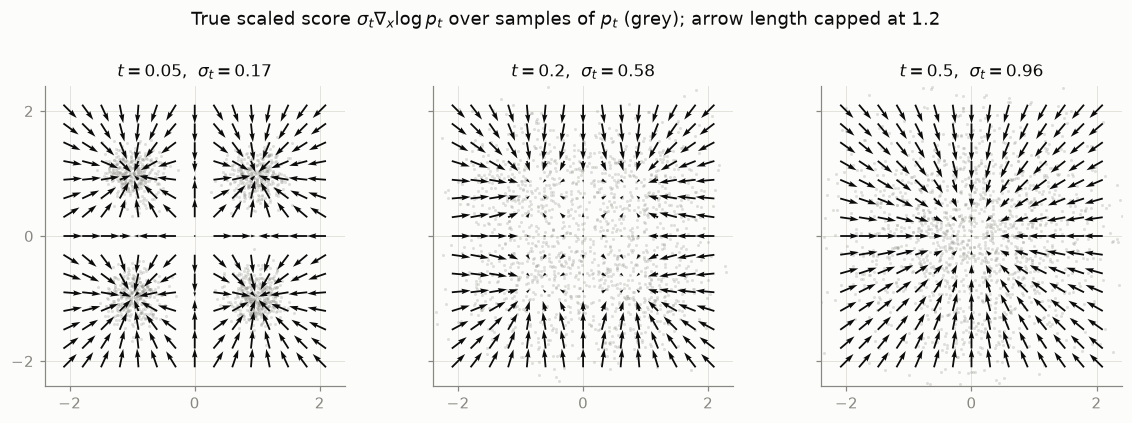

In [4]:
# sigma_t * score is O(1) at every t (it is -E[z | x_t]), so it is what the arrows show.
g1, g2 = np.meshgrid(np.linspace(-2.1, 2.1, 15), np.linspace(-2.1, 2.1, 15))
GRID_POINTS = torch.tensor(np.c_[g1.ravel(), g2.ravel()])
FIELD_TIMES = (0.05, 0.2, 0.5)
ARROW_CAP = 1.2


def scaled_field(score_fn, t):
    tt = torch.full((len(GRID_POINTS),), t)
    with torch.no_grad():
        return (sigma(tt)[:, None] * score_fn(GRID_POINTS, tt)).numpy()


def draw_field(ax, field, color, t):
    eps = torch.randn(1500, 2, generator=torch.Generator().manual_seed(0))
    tt = torch.full((1500,), t)
    xt = mean_coef(tt)[:, None] * reference[:1500] + sigma(tt)[:, None] * eps
    ax.scatter(xt[:, 0], xt[:, 1], s=4, color=MUTED, alpha=0.25, linewidths=0)
    length = np.linalg.norm(field, axis=1, keepdims=True)
    field = field * np.minimum(1.0, ARROW_CAP / np.maximum(length, 1e-12))  # cap long arrows so they don't overlap
    ax.quiver(g1, g2, field[:, 0], field[:, 1], color=color, angles="xy", scale_units="xy", scale=4, width=0.006)


fig, axes = plt.subplots(1, 3, figsize=(11, 3.7), sharey=True)
for ax, t in zip(axes, FIELD_TIMES):
    draw_field(ax, scaled_field(true_score, t), INK, t)
    square_panel(ax, rf"$t = {t}$,  $\sigma_t = {sigma(torch.tensor(t)):.2f}$")
fig.suptitle(r"True scaled score $\sigma_t\nabla_x\log p_t$ over samples of $p_t$ (grey); arrow length capped at 1.2",
             color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

## 2. Score network and the NGD closure

The network is an MLP taking $(x, t)$ through 3 → 8 → 2 layers with SiLU, for **50 parameters**. It outputs
$\mathrm{net}_\theta = \sigma_t s_\theta$. Each training step draws $t\sim\mathcal U(10^{-3}, 1)$, data $x_0$ and
noise $z$ for 256 samples. The closure returns the 512 residuals $\mathrm{net}_\theta(x_t,t) + z$:

```python
opt = NGD(model.parameters(), lr=0.5, damping=1e-3, metric="gauss_newton")
opt.step(lambda: (model.scaled(xt, t) + z).reshape(-1))
```

In [5]:
class ScoreNet(nn.Module):
    def __init__(self, hidden=8):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(3, hidden), nn.SiLU(), nn.Linear(hidden, 2))

    def scaled(self, x, t):  # sigma_t * s_theta(x, t)
        return self.net(torch.cat([x, t[:, None]], dim=1))

    def forward(self, x, t):  # the score s_theta(x, t)
        return self.scaled(x, t) / sigma(t)[:, None]


def make_model():
    torch.manual_seed(0)  # identical initial weights for every optimiser
    return ScoreNet()


def training_batch(n, generator):
    x0 = sample_data(n, generator)
    t = T_MIN + (1 - T_MIN) * torch.rand(n, generator=generator)
    z = torch.randn(n, 2, generator=generator)
    return mean_coef(t)[:, None] * x0 + sigma(t)[:, None] * z, t, z


EVAL = training_batch(4000, torch.Generator().manual_seed(7))


def dsm_loss(model):
    x, t, z = EVAL
    with torch.no_grad():
        return 0.5 * ((model.scaled(x, t) + z) ** 2).sum(1).mean().item()


def score_error(model):
    # 1/2 E sigma_t^2 ||s_theta - grad log p_t||^2 on the evaluation batch; zero for a perfect model
    x, t, _ = EVAL
    with torch.no_grad():
        return 0.5 * ((model.scaled(x, t) - sigma(t)[:, None] * true_score(x, t)) ** 2).sum(1).mean().item()


x, t, z = EVAL
dsm_floor = 0.5 * ((sigma(t)[:, None] * true_score(x, t) + z) ** 2).sum(1).mean().item()
print("parameters:", sum(p.numel() for p in make_model().parameters()))
print(f"DSM loss of the true score (the irreducible floor): {dsm_floor:.4f}")

parameters: 50
DSM loss of the true score (the irreducible floor): 0.1749


## 3. Train

Every run starts from the same weights and sees the same minibatches. As in the DDPM notebook, there are 300
steps for NGD, and 300 plus 3,000 for Adam. HHL uses 6 clock qubits, run both plain and with
`match_damping_to_clock=True`. The DDPM notebook explains why plain HHL drops most of the spectrum.

In [6]:
STEPS, BATCH, LR, DAMPING = 300, 256, 0.5, 1e-3


def train(make_optimizer, steps=STEPS):
    model = make_model()
    opt = make_optimizer(model.parameters())
    g = torch.Generator().manual_seed(1)
    history = [score_error(model)]
    start = time.perf_counter()
    for _ in range(steps):
        xt, t, z = training_batch(BATCH, g)
        if isinstance(opt, NGD):
            opt.step(lambda: (model.scaled(xt, t) + z).reshape(-1))
        else:
            opt.zero_grad()
            (0.5 * ((model.scaled(xt, t) + z) ** 2).sum(1).mean()).backward()
            opt.step()
        history.append(score_error(model))
    return {"model": model, "score_error": history, "seconds": time.perf_counter() - start}


def ngd(solver="direct"):
    return lambda p: NGD(p, lr=LR, damping=DAMPING, metric="gauss_newton", solver=solver)


runs = {
    "Adam": train(lambda p: torch.optim.Adam(p, lr=1e-2)),
    "Adam, 10x steps": train(lambda p: torch.optim.Adam(p, lr=1e-2), steps=10 * STEPS),
    "NGD (direct)": train(ngd()),
    "NGD (HHL, plain)": train(ngd(QiskitHHLSolver(num_clock_qubits=6))),
    "NGD (HHL)": train(ngd(QiskitHHLSolver(num_clock_qubits=6, match_damping_to_clock=True))),
}

print(f"{'run':<20}{'steps':>7}{'score error':>13}{'DSM loss':>10}{'DSM - floor':>13}{'time (s)':>10}")
for name, r in runs.items():
    dsm = dsm_loss(r["model"])
    print(f"{name:<20}{len(r['score_error']) - 1:>7}{r['score_error'][-1]:>13.4f}{dsm:>10.4f}{dsm - dsm_floor:>13.4f}"
          f"{r['seconds']:>10.2f}")

run                   steps  score error  DSM loss  DSM - floor  time (s)
Adam                    300       0.1097    0.2869       0.1120      1.25
Adam, 10x steps        3000       0.0552    0.2288       0.0539     11.81
NGD (direct)            300       0.0373    0.2130       0.0381      1.83
NGD (HHL, plain)        300       0.1484    0.3274       0.1525     18.24
NGD (HHL)               300       0.0636    0.2364       0.0615     17.10


The last two loss columns check Vincent's identity: *DSM loss − floor* matches the exact score error, up to
Monte-Carlo noise on the 4,000-sample evaluation batch. The score error is the quantity that matters, and unlike
the DSM loss it falls towards zero.

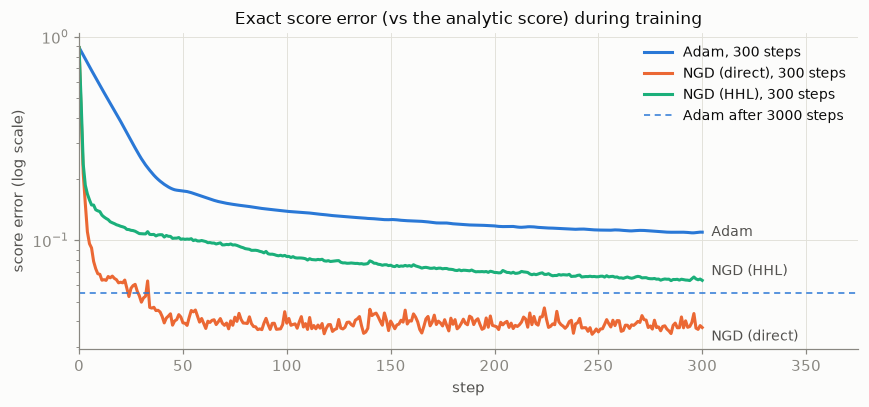

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.8))
steps = np.arange(STEPS + 1)
label_nudge = {"Adam": 0, "NGD (direct)": -6, "NGD (HHL)": 6}
for name in ("Adam", "NGD (direct)", "NGD (HHL)"):
    history = runs[name]["score_error"]
    ax.plot(steps, history, color=COLORS[name], label=f"{name}, {STEPS} steps")
    ax.annotate(name, (STEPS, history[-1]), xytext=(6, label_nudge[name]), textcoords="offset points",
                va="center", fontsize=9, color=INK_2)
adam_long = runs["Adam, 10x steps"]["score_error"][-1]
ax.axhline(adam_long, color=COLORS["Adam"], linewidth=1, linestyle=(0, (4, 3)), label=f"Adam after {10 * STEPS} steps")
ax.set(yscale="log", xlabel="step", ylabel="score error (log scale)", xlim=(0, STEPS * 1.25),
       title="Exact score error (vs the analytic score) during training")
ax.legend(loc="upper right", fontsize=9)
fig.tight_layout()
plt.show()

## 4. Learned versus true score field

The top row is the analytic field and the bottom row is the NGD (direct) model's. The tiny network captures the
four-way pull at small $t$ and the pull towards the centre at larger $t$.

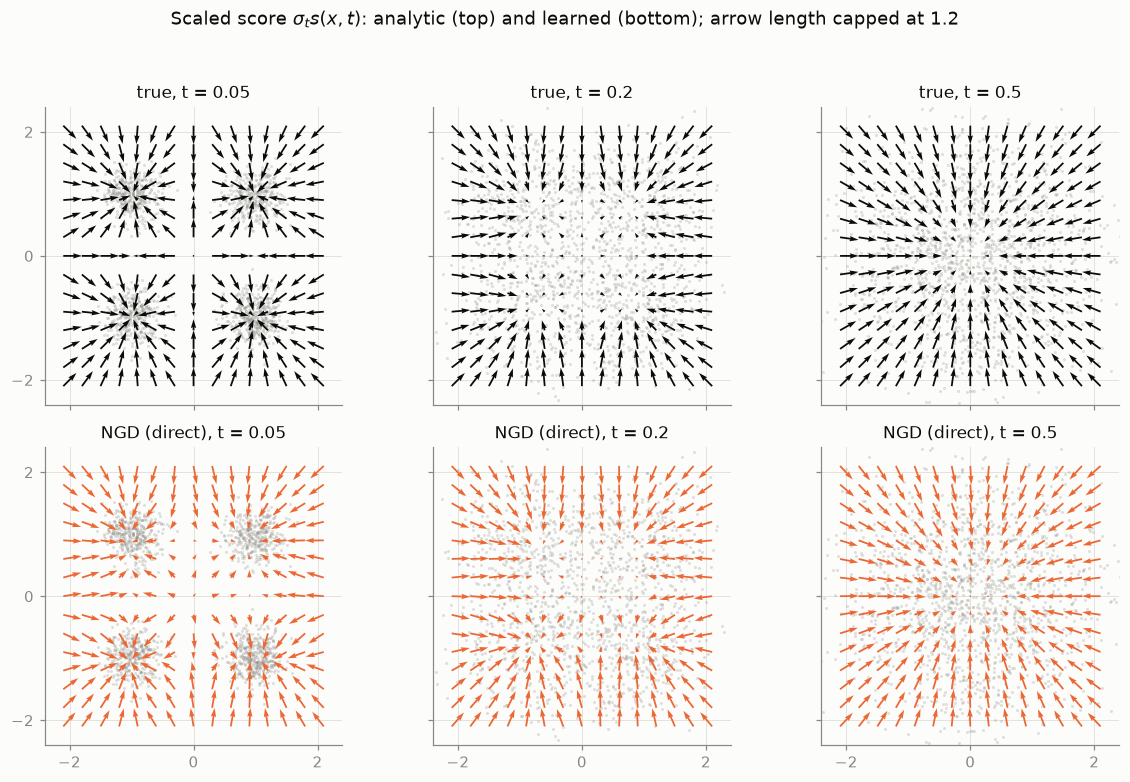

In [8]:
learned = runs["NGD (direct)"]["model"]
fig, axes = plt.subplots(2, 3, figsize=(11, 7.2), sharex=True, sharey=True)
for col, t in enumerate(FIELD_TIMES):
    draw_field(axes[0, col], scaled_field(true_score, t), INK, t)
    square_panel(axes[0, col], f"true, t = {t}")
    draw_field(axes[1, col], scaled_field(learned, t), COLORS["NGD (direct)"], t)
    square_panel(axes[1, col], f"NGD (direct), t = {t}")
fig.suptitle(r"Scaled score $\sigma_t s(x, t)$: analytic (top) and learned (bottom); arrow length capped at 1.2",
             color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

## 5. Three samplers

All three integrate from $t=1$ to $t=10^{-3}$ in 200 steps.

* **Reverse SDE** (Euler–Maruyama), the stochastic reverse of the forward process.
* **Probability-flow ODE** (Euler), a deterministic map from noise to data with the same marginals.
* **Predictor-corrector**: an Euler–Maruyama step followed by one Langevin step, using Song et al.'s step-size
  rule with signal-to-noise ratio 0.1.

A **true score** row runs the same samplers with the analytic score. It separates errors in the samplers from
errors in the learned score.

In [9]:
N_SAMPLER_STEPS = 200


@torch.no_grad()
def generate(score_fn, method, n=2000, seed=1, snr=0.1, return_path=False):
    g = torch.Generator().manual_seed(seed)
    x = torch.randn(n, 2, generator=g)
    path = [x.clone()]
    times = torch.linspace(1.0, T_MIN, N_SAMPLER_STEPS + 1)
    for i in range(N_SAMPLER_STEPS):
        t, dt = times[i], times[i + 1] - times[i]  # dt < 0: integrating backwards
        b, tt = beta(t), torch.full((n,), float(t))
        if method == "ode":
            x = x + (-0.5 * b * x - 0.5 * b * score_fn(x, tt)) * dt
        else:
            x = x + (-0.5 * b * x - b * score_fn(x, tt)) * dt + (b * -dt).sqrt() * torch.randn(n, 2, generator=g)
            if method == "pc" and i < N_SAMPLER_STEPS - 1:  # Langevin corrector at the next time
                score = score_fn(x, torch.full((n,), float(times[i + 1])))
                noise = torch.randn(n, 2, generator=g)
                alpha = 1 - beta(times[i + 1]) * -dt
                step = 2 * alpha * (snr * noise.norm(dim=1).mean() / score.norm(dim=1).mean()) ** 2
                x = x + step * score + (2 * step).sqrt() * noise
        path.append(x.clone())
    return torch.stack(path) if return_path else x


def mmd2(a, b, bandwidth=0.3):
    def k(u, v):
        return torch.exp(-torch.cdist(u, v) ** 2 / (2 * bandwidth**2)).mean()

    return (k(a, a) + k(b, b) - 2 * k(a, b)).item()


SAMPLERS = {"reverse SDE": "sde", "prob.-flow ODE": "ode", "pred.-corrector": "pc"}
score_fns = {"true score": true_score, **{name: r["model"] for name, r in runs.items()}}
print(f"MMD² between two independent data samples: {mmd2(sample_data(2000, torch.Generator().manual_seed(5)), reference):.4f}\n")
print(f"{'MMD² (lower is better)':<22}" + "".join(f"{s:>17}" for s in SAMPLERS))
for name, fn in score_fns.items():
    print(f"{name:<22}" + "".join(f"{mmd2(generate(fn, m), reference):>17.4f}" for m in SAMPLERS.values()))

MMD² between two independent data samples: 0.0011

MMD² (lower is better)      reverse SDE   prob.-flow ODE  pred.-corrector


true score                       0.0008           0.0015           0.0012


Adam                             0.1677           0.1718           0.1970


Adam, 10x steps                  0.0560           0.0463           0.0702


NGD (direct)                     0.0265           0.0406           0.0308


NGD (HHL, plain)                 0.2245           0.1463           0.2772


NGD (HHL)                        0.0736           0.0383           0.0903


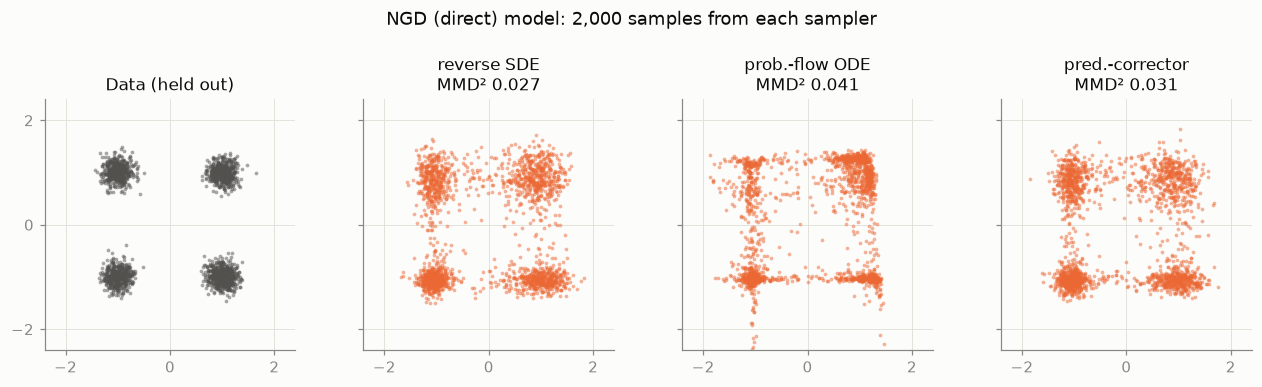

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3.3), sharey=True)
scatter_panel(axes[0], reference, INK_2, "Data (held out)")
for ax, (label, method) in zip(axes[1:], SAMPLERS.items()):
    points = generate(learned, method)
    scatter_panel(ax, points, COLORS["NGD (direct)"], f"{label}\nMMD² {mmd2(points, reference):.3f}")
fig.suptitle("NGD (direct) model: 2,000 samples from each sampler", color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.92))
plt.show()

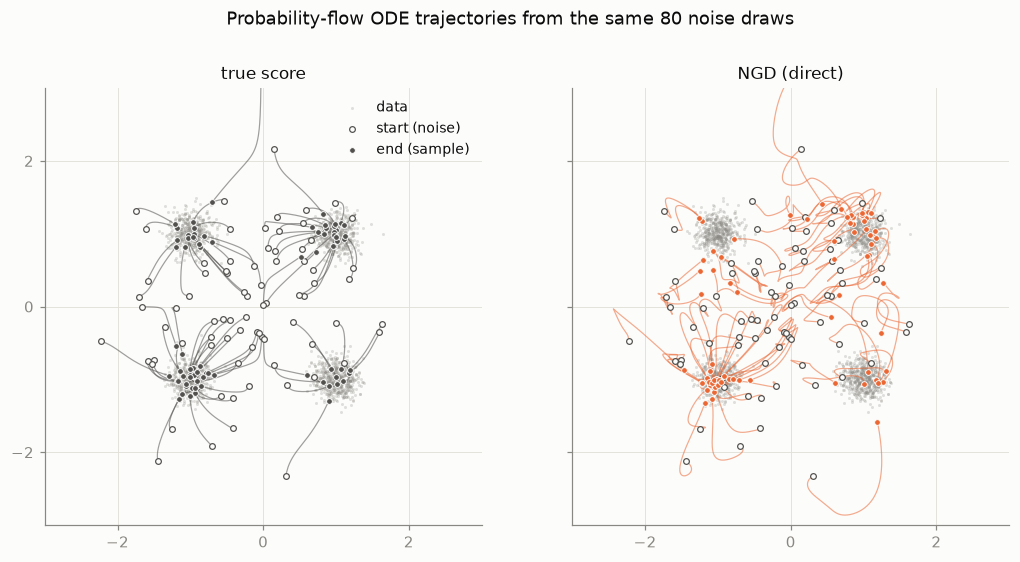

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharey=True)
for ax, (title, fn, color) in zip(axes, [("true score", true_score, INK_2),
                                         ("NGD (direct)", learned, COLORS["NGD (direct)"])]):
    path = generate(fn, "ode", n=80, seed=3, return_path=True).numpy()  # [steps + 1, n, 2]; same noise in both
    ax.scatter(reference[:, 0], reference[:, 1], s=4, color=MUTED, alpha=0.25, linewidths=0, label="data")
    for i in range(path.shape[1]):
        ax.plot(path[:, i, 0], path[:, i, 1], color=color, linewidth=0.8, alpha=0.55)
    ax.scatter(path[0, :, 0], path[0, :, 1], s=14, color=SURFACE, edgecolor=INK_2, linewidth=0.8, zorder=3,
               label="start (noise)")
    ax.scatter(path[-1, :, 0], path[-1, :, 1], s=14, color=color, edgecolor=SURFACE, linewidth=0.6, zorder=4,
               label="end (sample)")
    square_panel(ax, f"{title}")
    ax.set(xlim=(-3, 3), ylim=(-3, 3))
axes[0].legend(loc="upper right", fontsize=9)
fig.suptitle("Probability-flow ODE trajectories from the same 80 noise draws", color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

## Takeaways

- **NGD learns the score about 3× more accurately than Adam at the same step count.** After 300 steps, NGD with
  a direct solve reached a score error of 0.037, against 0.110 for Adam. Adam got to 0.055 after 3,000 steps. The
  network and minibatches match the DDPM notebook, and the ranking is the same.
- **Denoising score matching is a Gauss-Newton problem.** With $s_\theta = \mathrm{net}_\theta/\sigma_t$, the
  loss is $\tfrac12\|\mathrm{net}_\theta + z\|^2$, so `metric="gauss_newton"` applies directly. The table also
  confirms Vincent's identity numerically: DSM loss minus its floor of 0.175 matches the exact score error to
  within 0.005 in every run.
- **HHL needs `match_damping_to_clock`.** Plain 6-clock-qubit HHL was worse than Adam (score error 0.148). With
  clock-matched damping it reached 0.064, between Adam after 300 steps and after 3,000. The DDPM notebook explains
  the eigenvalue cut-off behind this.
- **The bottleneck is the score, not the sampler.** With the analytic score, all three samplers reach the
  data-versus-data noise floor (MMD² 0.0008–0.0015 against 0.0011). With learned scores, no sampler is best
  everywhere: the reverse SDE is best for the NGD (direct) model and the probability-flow ODE for the HHL model.
  The **Langevin corrector made every learned model worse**, because it runs MCMC towards whatever distribution
  the imperfect score defines. The deterministic **ODE** doesn't average score errors away with fresh noise,
  which shows as streaks between the modes and as looping trajectories next to the clean flow of the true score.

All runs use one seed.